# Visualization Principles

A chart is an argument made with data. A good chart answers one question quickly and honestly; a bad chart hides the answer, or suggests a wrong one. This lesson covers the principles that decide which chart to use and how to draw it.

**After this lesson you can:**

1. Choose a chart type from the analytical task (compare, distribute, relate, compose, trend).
2. Explain why position and length are read more accurately than angle, area and colour.
3. Remove chart clutter and put the message in the title.
4. Recognise misleading charts: truncated axes, dual axes, 3-D effects, cherry-picked ranges.

**Data:** Gapminder (life expectancy, fertility, population; 63 countries, 1955–2005) and NYC taxi trips.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

gap = pd.read_json(datasets.fetch("gapminder.json"))
REGIONS = {0: "South Asia", 1: "Europe & Central Asia", 2: "Sub-Saharan Africa", 3: "Americas",
           4: "East Asia & Pacific", 5: "Middle East & North Africa"}
gap["region"] = gap["cluster"].map(REGIONS)
gap.head(3)

,year,country,cluster,pop,life_expect,fertility,region
0,1955,Afghanistan,0,8891209,30.332,7.7,South Asia
1,1960,Afghanistan,0,9829450,31.997,7.7,South Asia
2,1965,Afghanistan,0,10997885,34.020,7.7,South Asia


## 1. Start from the Task, Not from the Chart

| Task | Question | Good charts |
| :--- | :--- | :--- |
| **compare** | which is bigger? | bar chart, dot plot |
| **distribution** | how are values spread? | histogram, box plot, ECDF |
| **relationship** | does X move with Y? | scatter plot, hexbin |
| **composition** | what are the parts of a whole? | stacked bar, (sometimes) pie with ≤ 3 parts |
| **trend** | how does it change over time? | line chart |

The figure answers five questions about the same dataset, one per task.

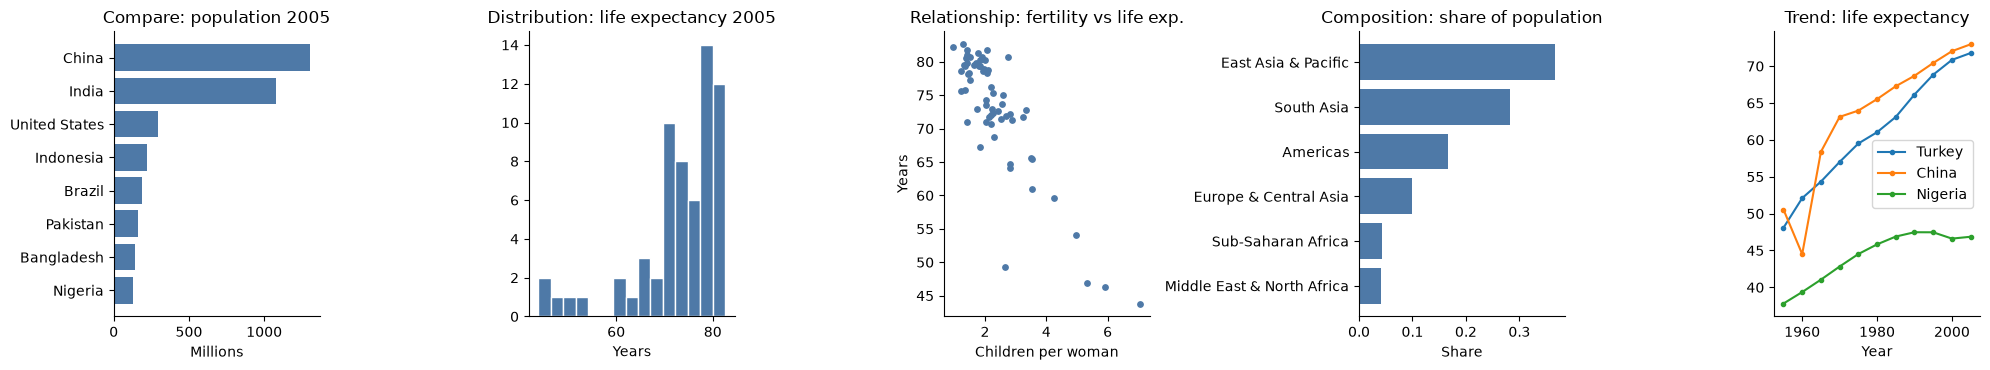

In [2]:
y2005 = gap[gap["year"] == 2005]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
top = y2005.nlargest(8, "pop").sort_values("pop")
axes[0].barh(top["country"], top["pop"] / 1e6, color="#4E79A7")
axes[0].set(title="Compare: population 2005", xlabel="Millions")
axes[1].hist(y2005["life_expect"], bins=15, color="#4E79A7", edgecolor="white")
axes[1].set(title="Distribution: life expectancy 2005", xlabel="Years")
axes[2].scatter(y2005["fertility"], y2005["life_expect"], s=15, color="#4E79A7")
axes[2].set(title="Relationship: fertility vs life exp.", xlabel="Children per woman", ylabel="Years")
comp = y2005.groupby("region")["pop"].sum().sort_values() / y2005["pop"].sum()
axes[3].barh(comp.index, comp.values, color="#4E79A7")
axes[3].set(title="Composition: share of population", xlabel="Share")
for c in ["Turkey", "China", "Nigeria"]:
    part = gap[gap["country"] == c]
    axes[4].plot(part["year"], part["life_expect"], marker=".", label=c)
axes[4].set(title="Trend: life expectancy", xlabel="Year")
axes[4].legend()
plt.tight_layout()
plt.show()

## 2. Perception: What the Eye Reads Accurately

Cleveland and McGill (1984) measured how accurately people compare values encoded in different ways. From most to least accurate: **position on a common scale**, length, angle, area, colour saturation. The same five values are shown below as bars, as pie slices and as circle areas. Try to rank them in each panel.

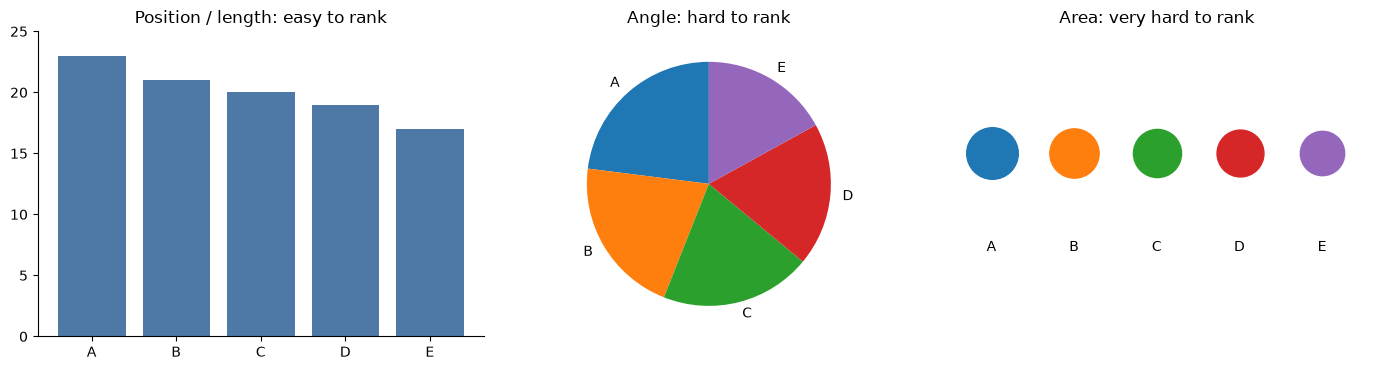

true values: {'A': 23, 'B': 21, 'C': 20, 'D': 19, 'E': 17}


In [3]:
values = pd.Series([23, 21, 20, 19, 17], index=list("ABCDE"))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].bar(values.index, values, color="#4E79A7")
axes[0].set(title="Position / length: easy to rank", ylim=(0, 25))
axes[1].pie(values, labels=values.index, colors=plt.cm.tab10.colors[:5], startangle=90)
axes[1].set(title="Angle: hard to rank")
for i, (k, v) in enumerate(values.items()):
    axes[2].scatter(i, 0, s=v * 60, color=plt.cm.tab10.colors[i])
    axes[2].text(i, -0.08, k, ha="center")
axes[2].set(title="Area: very hard to rank", xlim=(-0.7, 4.7), ylim=(-0.15, 0.1))
axes[2].axis("off")
plt.tight_layout()
plt.show()
print("true values:", values.to_dict())

In the bar chart, the order A > B > C > D > E is obvious. In the pie and the circles, values that differ by 10 % look almost equal. Use position or length for the comparison that matters most.

## 3. Remove Clutter, State the Message

Every element should help the reader. Remove heavy grids, borders, 3-D effects and legends that the reader must decode; label directly; and write the **conclusion** as the title.

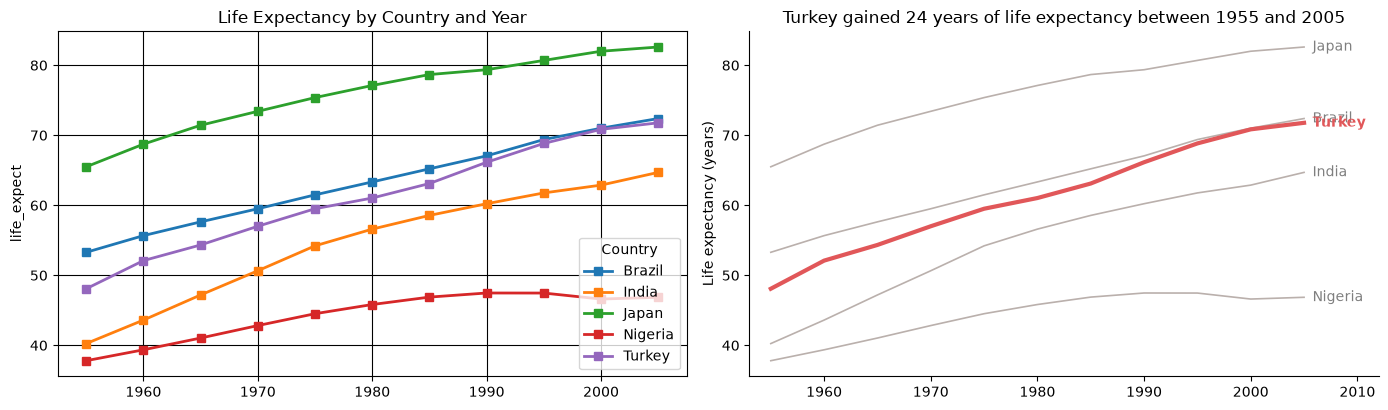

In [4]:
trend = gap[gap["country"].isin(["Turkey", "Brazil", "India", "Japan", "Nigeria"])].pivot(index="year", columns="country", values="life_expect")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
for c in trend.columns:
    ax1.plot(trend.index, trend[c], marker="s", lw=2)
ax1.grid(True, color="black", lw=0.8)
ax1.legend(trend.columns, loc="lower right", frameon=True, title="Country")
ax1.set(title="Life Expectancy by Country and Year", ylabel="life_expect")
for side in ("top", "right"):
    ax1.spines[side].set_visible(True)

highlight = "Turkey"
for c in trend.columns:
    is_h = c == highlight
    ax2.plot(trend.index, trend[c], lw=3 if is_h else 1.2, color="#E15759" if is_h else "#BAB0AC")
    ax2.text(trend.index[-1] + 0.8, trend[c].iloc[-1], c, va="center", color="#E15759" if is_h else "#7F7F7F",
             fontweight="bold" if is_h else "normal")
gain = trend[highlight].iloc[-1] - trend[highlight].iloc[0]
ax2.set(title=f"Turkey gained {gain:.0f} years of life expectancy between 1955 and 2005", ylabel="Life expectancy (years)",
        xlim=(1953, 2012))
plt.tight_layout()
plt.show()

The right chart uses colour for **one** purpose (the country in focus), labels the lines directly, and tells the reader what to see.

## 4. Honest Scales

The same numbers can tell different stories depending on the axis. Bars encode values by **length**, so a bar axis must start at zero. Line charts show change, so a non-zero baseline is acceptable, if it is clearly labelled.

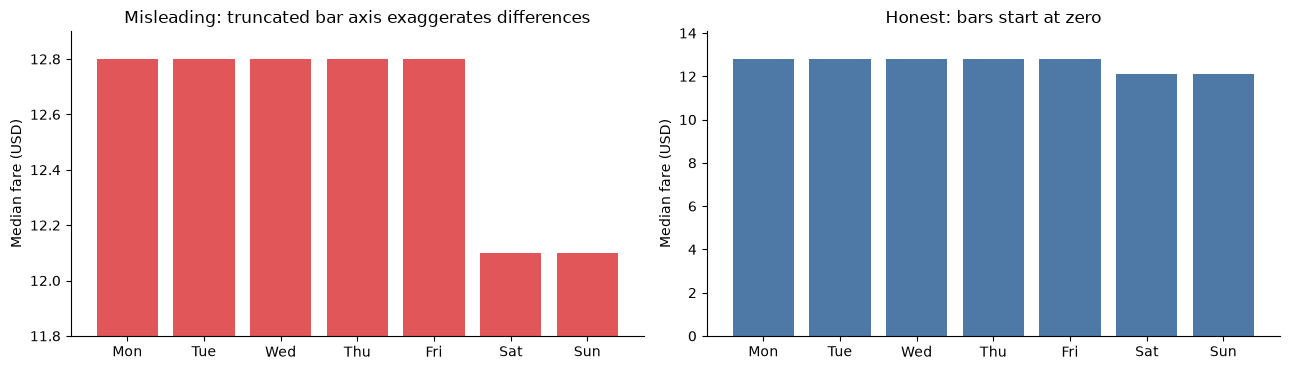

largest difference between days: 5.8 %


In [5]:
taxi = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "fare_amount"])
taxi = taxi[taxi["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")]
weekly = taxi.groupby(taxi["tpep_pickup_datetime"].dt.day_name())["fare_amount"].median()
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = weekly.reindex(days)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.bar([d[:3] for d in days], weekly, color="#E15759")
ax1.set(ylim=(weekly.min() - 0.3, weekly.max() + 0.1), title="Misleading: truncated bar axis exaggerates differences")
ax2.bar([d[:3] for d in days], weekly, color="#4E79A7")
ax2.set(ylim=(0, weekly.max() * 1.1), title="Honest: bars start at zero")
for ax in (ax1, ax2):
    ax.set_ylabel("Median fare (USD)")
plt.tight_layout()
plt.show()
print(f"largest difference between days: {100 * (weekly.max() / weekly.min() - 1):.1f} %")

| Trick | Why it misleads | Fix |
| :--- | :--- | :--- |
| truncated bar axis | lengths no longer proportional to values | start bars at 0, or use a dot plot |
| dual y-axes | two arbitrary scales create fake correlations | two panels, or index both series to 100 |
| 3-D bars and pies | perspective distorts lengths and areas | flat 2-D charts |
| cherry-picked time range | hides the longer trend | show enough context; mark the period in focus |
| area/size for 1-D data | area grows with the square of the radius | use length |

*Insight: Pick the chart from the question, encode the most important comparison with position or length, remove what does not carry information, and write the conclusion in the title. Check every axis: a chart must not be technically correct and visually false.*

## Real-World Use Case or Analogy

A chart is like a **road sign**: drivers must understand it in a second, so it shows one message, uses standard shapes, and does not decorate. A road sign that is pretty but ambiguous is dangerous; a chart that is pretty but misleading leads to bad decisions.

Executive dashboards, scientific papers and newspaper graphics follow these principles (Tufte, Cleveland, the Financial Times *Visual Vocabulary*). Many companies publish internal chart style guides based on them.